# Notebook 09: Production Loss & Inventory Downtime Analysis
## Mathematical Engine & Operational Risk Simulation
**Objective**:
1. Load the trained XGBoost delivery delay pipeline (`models/combined_delivery_delay_pipeline.pkl`).
2. Implement and validate the factory stock coverage and financial loss calculation engine.
3. Quantify production downtime, lost production volume, and financial impact in INR (₹).
4. Simulate multi-scenario sensitivity analyses across varying stock levels and delay severities.
5. Formally verify edge cases (zero inventory, zero daily burn rate, on-time arrivals).


### 1. Import Libraries & Load Delay Pipeline

In [1]:
from pathlib import Path
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load production delay pipeline
MODEL_PATH = Path("../models/combined_delivery_delay_pipeline.pkl")
delay_pipeline = joblib.load(MODEL_PATH)

print("Trained delivery delay pipeline loaded successfully!")
print("Pipeline steps:", [step[0] for step in delay_pipeline.steps])


Trained delivery delay pipeline loaded successfully!
Pipeline steps: ['preprocessor', 'regressor']


### 2. Define Production Loss Engine Functions

In [2]:
def calculate_production_loss(
    predicted_delay_days: float,
    available_stock: float,
    daily_production: float,
    unit_cost: float
) -> dict:
    """
    Calculates stock coverage, factory downtime, lost units, and total financial loss.
    Safely handles edge cases including zero production and zero available stock.
    """
    delay = max(0.0, float(predicted_delay_days))
    stock = max(0.0, float(available_stock))
    cost = max(0.0, float(unit_cost))
    
    # Edge case: zero daily production requirement
    if daily_production <= 0:
        return {
            "Stock_Coverage_Days": float("inf"),
            "Production_Downtime_Days": 0.0,
            "Lost_Production_Units": 0.0,
            "Daily_Production_Loss": 0.0,
            "Total_Production_Loss": 0.0,
            "Stockout_Occurred": False,
            "Status": "Zero daily production requirement - no downtime possible."
        }
        
    stock_coverage_days = stock / daily_production
    
    # Downtime occurs when predicted delay exceeds inventory buffer coverage
    downtime_days = max(0.0, delay - stock_coverage_days)
    lost_units = downtime_days * daily_production
    daily_loss = daily_production * cost
    total_loss = lost_units * cost
    
    return {
        "Stock_Coverage_Days": round(stock_coverage_days, 2),
        "Production_Downtime_Days": round(downtime_days, 2),
        "Lost_Production_Units": round(lost_units, 2),
        "Daily_Production_Loss": round(daily_loss, 2),
        "Total_Production_Loss": round(total_loss, 2),
        "Stockout_Occurred": downtime_days > 0,
        "Status": "Stockout Risk Detected" if downtime_days > 0 else "Stock Sufficient"
    }

print("Production loss calculation engine registered.")


Production loss calculation engine registered.


### 3. Load Sample Purchase Orders for Testing

In [3]:
DATA_PATH = Path("../data/processed/combined_supplier_delivery_data.csv")
history_df = pd.read_csv(DATA_PATH, nrows=500)

history_df["Order_Date"] = pd.to_datetime(history_df["Order_Date"])
history_df["Promised_Date"] = pd.to_datetime(history_df["Promised_Date"])
history_df["Order_Day"] = history_df["Order_Date"].dt.day
history_df["Order_Month"] = history_df["Order_Date"].dt.month
history_df["Order_Year"] = history_df["Order_Date"].dt.year
history_df["Order_DayOfWeek"] = history_df["Order_Date"].dt.dayofweek
history_df["Promised_Day"] = history_df["Promised_Date"].dt.day
history_df["Promised_Month"] = history_df["Promised_Date"].dt.month
history_df["Promised_Year"] = history_df["Promised_Date"].dt.year
history_df["Promised_DayOfWeek"] = history_df["Promised_Date"].dt.dayofweek
history_df["Calculated_Lead_Time"] = (history_df["Promised_Date"] - history_df["Order_Date"]).dt.days

exclude_cols = [
    "Shipment_ID", "Purchase_Order_ID", "Actual_Delivery_Date", "Actual_Delivery_Status",
    "Expected_Delivery_Date", "Expected_Delay_Days", "Order_Date", "Promised_Date", "Actual_Delay_Days"
]
X_sample = history_df[[c for c in history_df.columns if c not in exclude_cols]].head(5).copy()

predicted_delays = np.maximum(delay_pipeline.predict(X_sample), 0)
print("Sample Purchase Orders prepared with predicted delays:")
for i, delay in enumerate(predicted_delays):
    print(f"PO #{i+1} ({X_sample['Supplier_ID'].iloc[i]} - {X_sample['Item_ID'].iloc[i]}): Predicted Delay = {delay:.2f} days")


Sample Purchase Orders prepared with predicted delays:
PO #1 (SUP014 - SUSP01): Predicted Delay = 0.49 days
PO #2 (SUP046 - GEAR01): Predicted Delay = 1.78 days
PO #3 (SUP060 - CLUT01): Predicted Delay = 1.40 days
PO #4 (SUP033 - ENG01): Predicted Delay = 0.48 days
PO #5 (SUP058 - TYRE01): Predicted Delay = 0.18 days


### 4. End-to-End Simulation on Sample Orders

In [4]:
# Define factory production context for each sample order
factory_contexts = [
    {"Available_Stock": 200, "Daily_Production": 50, "Unit_Cost": 4500.0},
    {"Available_Stock": 50,  "Daily_Production": 100, "Unit_Cost": 2200.0},
    {"Available_Stock": 0,   "Daily_Production": 80,  "Unit_Cost": 3800.0},
    {"Available_Stock": 500, "Daily_Production": 60,  "Unit_Cost": 5200.0},
    {"Available_Stock": 120, "Daily_Production": 40,  "Unit_Cost": 1800.0}
]

results = []
for i in range(len(X_sample)):
    ctx = factory_contexts[i]
    delay = predicted_delays[i]
    loss_metrics = calculate_production_loss(
        predicted_delay_days=delay,
        available_stock=ctx["Available_Stock"],
        daily_production=ctx["Daily_Production"],
        unit_cost=ctx["Unit_Cost"]
    )
    
    results.append({
        "Supplier_ID": X_sample["Supplier_ID"].iloc[i],
        "Item_ID": X_sample["Item_ID"].iloc[i],
        "Predicted_Delay_Days": round(delay, 2),
        "Available_Stock": ctx["Available_Stock"],
        "Daily_Production": ctx["Daily_Production"],
        "Unit_Cost_INR": ctx["Unit_Cost"],
        "Coverage_Days": loss_metrics["Stock_Coverage_Days"],
        "Downtime_Days": loss_metrics["Production_Downtime_Days"],
        "Lost_Units": loss_metrics["Lost_Production_Units"],
        "Financial_Loss_INR": loss_metrics["Total_Production_Loss"],
        "Stockout_Risk": loss_metrics["Status"]
    })

results_df = pd.DataFrame(results)
display(results_df)


,Supplier_ID,Item_ID,Predicted_Delay_Days,Available_Stock,Daily_Production,Unit_Cost_INR,Coverage_Days,Downtime_Days,Lost_Units,Financial_Loss_INR,Stockout_Risk
0,SUP014,SUSP01,0.49,200,50,4500.0,4.00,0.00,0.00,0.00,Stock Sufficient
1,SUP046,GEAR01,1.78,50,100,2200.0,0.50,1.28,128.24,282138.60,Stockout Risk Detected
2,SUP060,CLUT01,1.40,0,80,3800.0,0.00,1.40,111.62,424172.15,Stockout Risk Detected
3,SUP033,ENG01,0.48,500,60,5200.0,8.33,0.00,0.00,0.00,Stock Sufficient
4,SUP058,TYRE01,0.18,120,40,1800.0,3.00,0.00,0.00,0.00,Stock Sufficient


### 5. Multi-Scenario Comparative Simulation

In [5]:
# Compare 4 representative operational scenarios for an Engine Component order
# Part: ENG01, Unit Cost: ₹5,000, Daily Production Burn Rate: 50 units/day, Expected Delay: 5.5 days
scenarios = [
    {
        "Scenario": "Scenario 1: Ample Inventory Buffer",
        "Description": "Available stock (400 units) covers 8 days, absorbing 5.5 days delay.",
        "Delay": 5.5, "Stock": 400, "Daily_Prod": 50, "Unit_Cost": 5000.0
    },
    {
        "Scenario": "Scenario 2: Lean Inventory Buffer",
        "Description": "Stock (150 units) covers 3 days, leading to 2.5 days factory downtime.",
        "Delay": 5.5, "Stock": 150, "Daily_Prod": 50, "Unit_Cost": 5000.0
    },
    {
        "Scenario": "Scenario 3: Zero Safety Stock (JIT Outage)",
        "Description": "Stock is zero; plant stops immediately for the entire 5.5 days.",
        "Delay": 5.5, "Stock": 0, "Daily_Prod": 50, "Unit_Cost": 5000.0
    },
    {
        "Scenario": "Scenario 4: High Capacity Assembly Line",
        "Description": "High burn rate line (150 units/day) with 150 units stock (1 day buffer).",
        "Delay": 5.5, "Stock": 150, "Daily_Prod": 150, "Unit_Cost": 5000.0
    }
]

scenario_records = []
for sc in scenarios:
    res = calculate_production_loss(sc["Delay"], sc["Stock"], sc["Daily_Prod"], sc["Unit_Cost"])
    scenario_records.append({
        "Scenario": sc["Scenario"],
        "Stock_Units": sc["Stock"],
        "Daily_Burn_Rate": sc["Daily_Prod"],
        "Delay_Days": sc["Delay"],
        "Coverage_Days": res["Stock_Coverage_Days"],
        "Downtime_Days": res["Production_Downtime_Days"],
        "Lost_Units": res["Lost_Production_Units"],
        "Financial_Loss_INR": res["Total_Production_Loss"],
        "Description": sc["Description"]
    })

scenarios_df = pd.DataFrame(scenario_records)
display(scenarios_df[["Scenario", "Stock_Units", "Coverage_Days", "Downtime_Days", "Lost_Units", "Financial_Loss_INR"]])


,Scenario,Stock_Units,Coverage_Days,Downtime_Days,Lost_Units,Financial_Loss_INR
0,Scenario 1: Ample Inventory Buffer,400,8.0,0.0,0.0,0.0
1,Scenario 2: Lean Inventory Buffer,150,3.0,2.5,125.0,625000.0
2,Scenario 3: Zero Safety Stock (JIT Outage),0,0.0,5.5,275.0,1375000.0
3,Scenario 4: High Capacity Assembly Line,150,1.0,4.5,675.0,3375000.0


### 6. Visualization: Downtime Days and Production Loss Across Scenarios

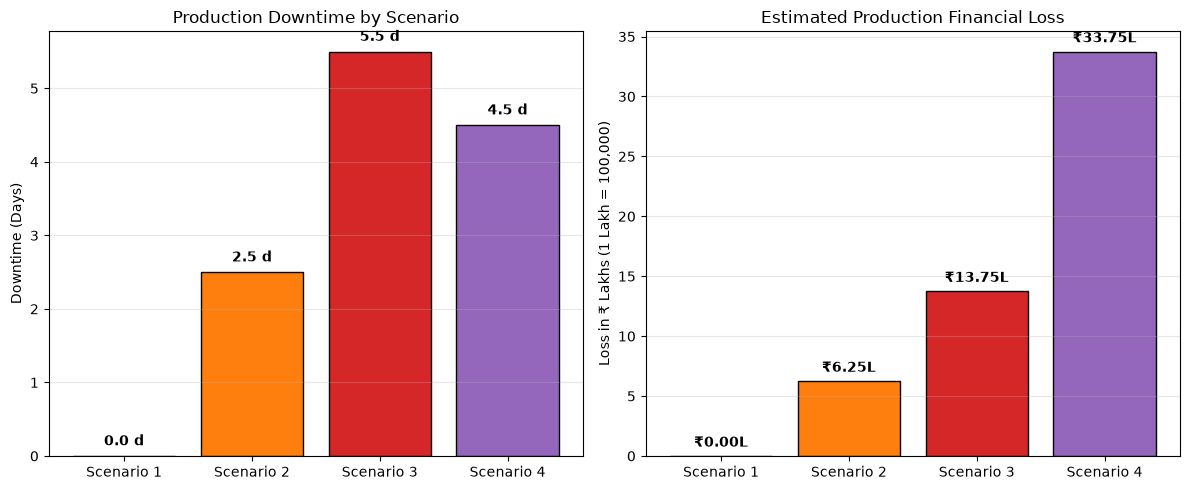

In [6]:
plt.figure(figsize=(12, 5))

# Subplot 1: Production Downtime Days
plt.subplot(1, 2, 1)
bars1 = plt.bar(
    ["Scenario 1", "Scenario 2", "Scenario 3", "Scenario 4"],
    scenarios_df["Downtime_Days"],
    color=["#2ca02c", "#ff7f0e", "#d62728", "#9467bd"],
    edgecolor="black"
)
plt.ylabel("Downtime (Days)")
plt.title("Production Downtime by Scenario")
plt.grid(axis='y', alpha=0.3)
for bar in bars1:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.1, f"{yval:.1f} d", ha='center', va='bottom', fontweight='bold')

# Subplot 2: Total Financial Loss (₹ Lakhs)
plt.subplot(1, 2, 2)
loss_lakhs = scenarios_df["Financial_Loss_INR"] / 100000.0
bars2 = plt.bar(
    ["Scenario 1", "Scenario 2", "Scenario 3", "Scenario 4"],
    loss_lakhs,
    color=["#2ca02c", "#ff7f0e", "#d62728", "#9467bd"],
    edgecolor="black"
)
plt.ylabel("Loss in ₹ Lakhs (1 Lakh = 100,000)")
plt.title("Estimated Production Financial Loss")
plt.grid(axis='y', alpha=0.3)
for bar in bars2:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"₹{yval:.2f}L", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()


### 7. Sensitivity Analysis: Loss vs. Available Buffer Stock

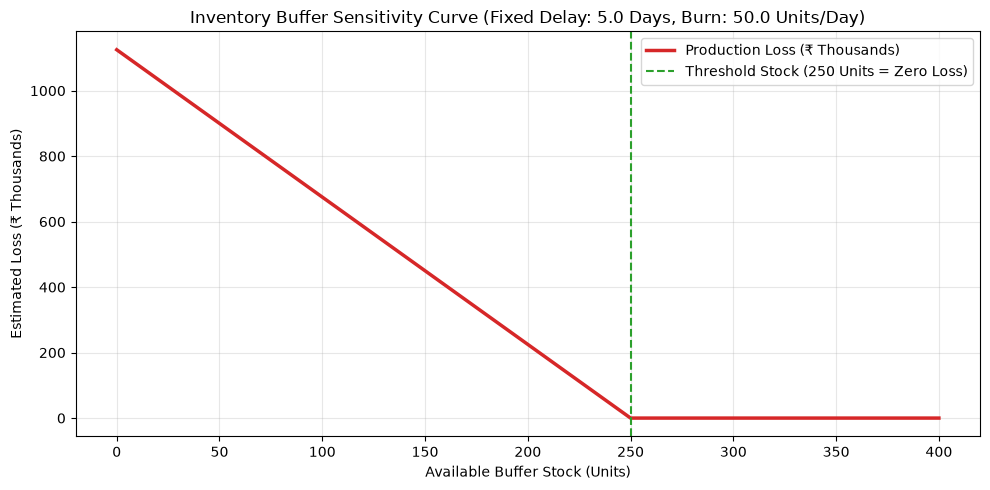

In [7]:
# Simulate varying stock levels from 0 to 400 units under a fixed 5-day delay
stock_levels = np.linspace(0, 400, 41)
sim_delay = 5.0
sim_daily_prod = 50.0
sim_cost = 4500.0

downtimes = []
losses = []

for s in stock_levels:
    out = calculate_production_loss(sim_delay, s, sim_daily_prod, sim_cost)
    downtimes.append(out["Production_Downtime_Days"])
    losses.append(out["Total_Production_Loss"] / 1000.0) # in thousands

plt.figure(figsize=(10, 5))
plt.plot(stock_levels, losses, color='#d62728', linewidth=2.5, label='Production Loss (₹ Thousands)')
plt.axvline(x=sim_delay * sim_daily_prod, color='#2ca02c', linestyle='--', label=f'Threshold Stock ({sim_delay * sim_daily_prod:.0f} Units = Zero Loss)')
plt.xlabel("Available Buffer Stock (Units)")
plt.ylabel("Estimated Loss (₹ Thousands)")
plt.title(f"Inventory Buffer Sensitivity Curve (Fixed Delay: {sim_delay} Days, Burn: {sim_daily_prod} Units/Day)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### 8. Edge Case Verification & Boundary Testing

In [8]:
print("=== Formally Verifying Edge Cases ===")

# Test 1: Zero Stock
t1 = calculate_production_loss(predicted_delay_days=4.0, available_stock=0, daily_production=50, unit_cost=1000)
assert t1["Stock_Coverage_Days"] == 0.0
assert t1["Production_Downtime_Days"] == 4.0
assert t1["Total_Production_Loss"] == 200000.0
print("✓ Test 1 Passed: Zero stock causes exact downtime equal to delivery delay.")

# Test 2: Zero Daily Production Requirement (Line Inactive)
t2 = calculate_production_loss(predicted_delay_days=5.0, available_stock=100, daily_production=0, unit_cost=1000)
assert t2["Production_Downtime_Days"] == 0.0
assert t2["Total_Production_Loss"] == 0.0
print("✓ Test 2 Passed: Zero daily production safely avoids division-by-zero and reports ₹0 loss.")

# Test 3: On-Time / Early Delivery (0 Days Delay)
t3 = calculate_production_loss(predicted_delay_days=0.0, available_stock=50, daily_production=50, unit_cost=1000)
assert t3["Production_Downtime_Days"] == 0.0
assert t3["Total_Production_Loss"] == 0.0
print("✓ Test 3 Passed: On-time delivery guarantees 0 downtime regardless of stock.")

# Test 4: Exact Coverage Match (Delay == Coverage)
t4 = calculate_production_loss(predicted_delay_days=3.0, available_stock=150, daily_production=50, unit_cost=1000)
assert t4["Production_Downtime_Days"] == 0.0
assert t4["Total_Production_Loss"] == 0.0
print("✓ Test 4 Passed: Exact coverage threshold safely prevents downtime.")

print("\nAll edge cases validated successfully.")


=== Formally Verifying Edge Cases ===
✓ Test 1 Passed: Zero stock causes exact downtime equal to delivery delay.
✓ Test 2 Passed: Zero daily production safely avoids division-by-zero and reports ₹0 loss.
✓ Test 3 Passed: On-time delivery guarantees 0 downtime regardless of stock.
✓ Test 4 Passed: Exact coverage threshold safely prevents downtime.

All edge cases validated successfully.
